# Data Visualization — Quiz (Lectures 1–7)

**Time:** 90 minutes 
**Tools:** Plotly only (`plotly.express` first, then `update_traces` / `update_layout` / `update_xaxes` / `update_yaxes`)

**Your task:** answer each analytical question with **one polished, explanatory visualization**. For every question **you decide which chart type fits best** — and justify the choice in one or two sentences.

**Every figure must have:**
1. An **insight title** that states the finding, not just the variables
2. `template='plotly_white'` and a decluttered layout (no unnecessary gridlines, legends or axis titles)
3. A **CVD-safe palette** — no red/green; grey for context + one accent colour where it helps
4. Colour that **encodes meaning**, not decoration
5. Direct labels or annotations where they help the reader

**Chart types covered in the course** — choose from these:
line chart · sorted bar chart · stacked / 100% stacked bar chart · scatter plot · bubble chart · histogram · box plot · violin plot · choropleth map · treemap

> 💡 Each question has one chart type that fits it best, and the questions together cover most of the list above. If two of your answers use the same chart type, check the question again.


**Submit:** this notebook pushed to your personal repo as `quiz/dataviz_quiz.ipynb`

## The dataset — World Population 1970–2022

**Source:** [World Population Dataset](https://www.kaggle.com/datasets/iamsouravbanerjee/world-population-dataset) on Kaggle, compiled from Worldometer (UN World Population Prospects estimates). **234 rows × 16 columns — one row per country or territory, no missing values.**

| Column | Type | Description |
|---|---|---|
| `Country`, `Capital` | categorical | Country / territory and its capital |
| `Continent` | categorical | Africa, Asia, Europe, North America, Oceania, South America |
| `CCA3` | spatial | ISO-3 country code — use with `locationmode='ISO-3'` |
| `1970 Population` … `2022 Population` | temporal | Population in 1970, 1980, 1990, 2000, 2010, 2015, 2020, 2022 |
| `Area` | numerical | Land area in km² |
| `Density` | numerical | People per km² (2022) |
| `World share (%)` | numerical | Share of world population in 2022 |
| `Rank` | numerical | Rank by 2022 population |

**The next setup cell also gives you `df_long` — the same data in **tidy (long) format** with one row per country per year. Use `df` for one-year questions and `df_long` for questions about change over time**

In [3]:
import pandas as pd
import plotly.express as px
import numpy as np

df = pd.read_csv('world_population.csv')

# Shorter column names
df = df.rename(columns={'Country/Territory': 'Country', 'Area (km²)': 'Area',
                        'Density (per km²)': 'Density', 'World Population Percentage': 'World share (%)'})

# Tidy (long) version: one row per country per year
year_cols = [c for c in df.columns if c.endswith('Population')]
df_long = df.melt(id_vars=['CCA3', 'Country', 'Continent'], value_vars=year_cols,
                  var_name='Year', value_name='Population')

df_long['Year'] = df_long['Year'].str[:4].astype(int)     # '2022 Population' → 2022

print(df.shape, df_long.shape)


(234, 16) (1872, 5)


---
## Q1 — Which continent is growing fastest?

How has the population of each continent **grown since 1970, relative to its 1970 size** — and which continent is growing fastest?


**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* : 
I chose a line chart because it clearly shows how population growth has changed across continents from 1970 to 2022. I used 1970 as the baseline (100) to compare relative population growth. Different colours represent different continents, making it easy to identify which continent experienced the fastest growth.

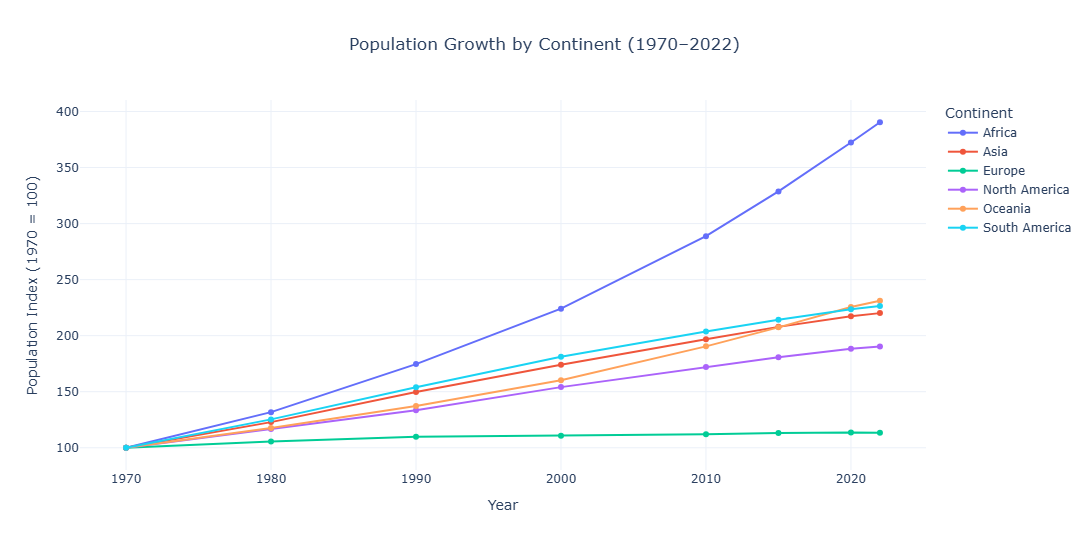

In [4]:
# Q1
# YOUR CODE HERE
continent_pop = df_long.groupby(
    ['Continent', 'Year']
)['Population'].sum().reset_index()

# Get the population in 1970 for each continent
base_population = continent_pop[
    continent_pop['Year'] == 1970
][['Continent', 'Population']]

base_population = base_population.rename(
    columns={'Population': 'Base Population'}
)

# Merge baseline population
continent_pop = continent_pop.merge(
    base_population, on='Continent'
)

# Calculate population index (1970 = 100)
continent_pop['Growth Index'] = (
    continent_pop['Population'] /
    continent_pop['Base Population']
) * 100

# Create line chart
fig = px.line(
    continent_pop,
    x='Year',
    y='Growth Index',
    color='Continent',
    markers=True,
    title='Population Growth by Continent (1970–2022)',
    labels={
        'Year': 'Year',
        'Growth Index': 'Population Index (1970 = 100)'
    },
    template='plotly_white'
)

fig.update_layout(
    title_x=0.5,
    height=550
)

fig.show()
  


---
## Q2 — Which countries added the most people?

Which **15 countries added the most people** between 1970 and 2022 — and how many of them are in **Africa**?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* : I chose a horizontal bar chart because it makes it easy to compare population increases across the 15 countries. The countries are sorted in descending order, with the largest increase at the top. Different colours represent continents, making it easier to identify the African countries among the top 15. I used population increase (2022 population minus 1970 population) as the measurement.

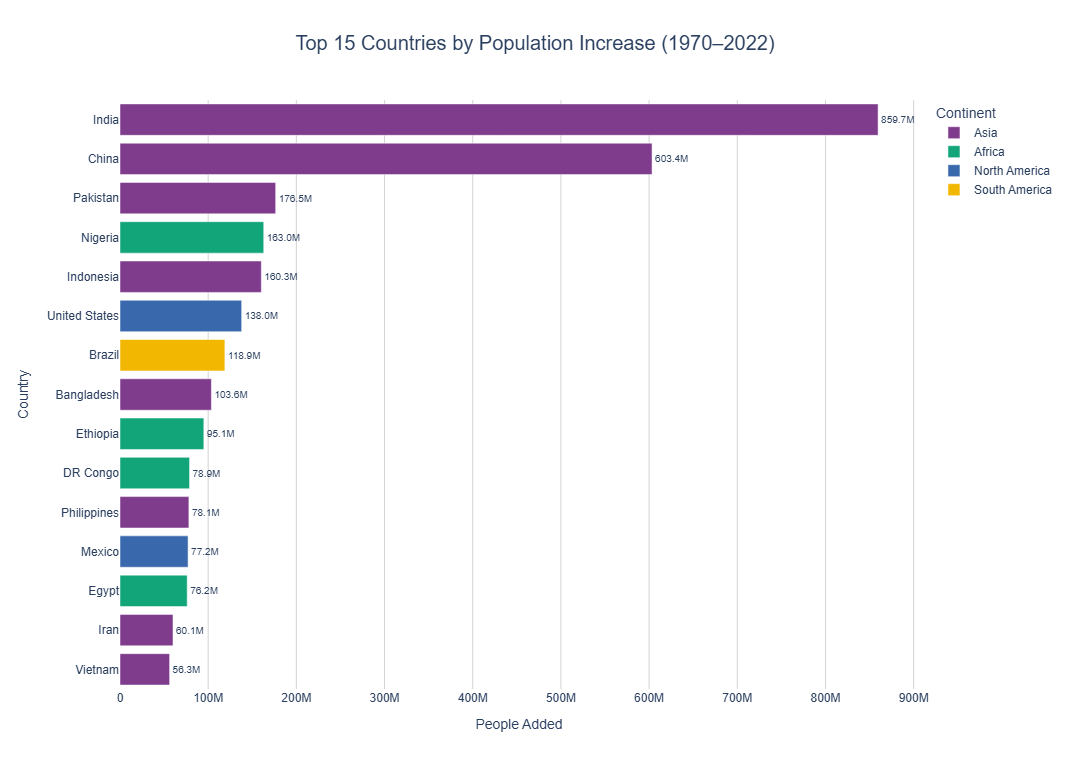

Q2: POPULATION INCREASE ANALYSIS

African countries in the top 15: 4

Top 15 countries:
      Country     Continent  Population Added
        India          Asia         859671872
        China          Asia         603352887
     Pakistan          Asia         176533990
      Nigeria        Africa         162971948
    Indonesia          Asia         160272945
United States North America         137961517
       Brazil South America         118943623
   Bangladesh          Asia         103644512
     Ethiopia        Africa          95071678
     DR Congo        Africa          78858479
  Philippines          Asia          78123423
       Mexico North America          77214819
        Egypt        Africa          76208117
         Iran          Asia          60100865
      Vietnam          Asia          56258007

African countries in the top 15:
['Nigeria', 'Ethiopia', 'DR Congo', 'Egypt']


In [5]:
# 1. Calculate population increase (1970–2022)
df['Population Added'] = (
    df['2022 Population'] - df['1970 Population']
)

# 2. Select the top 15 countries
top15 = df.nlargest(15, 'Population Added').copy()

# 3. Count African countries
africa_count = (
    top15['Continent'] == 'Africa'
).sum()

# 4. Sort countries for ranking (smallest at bottom)
top15_sorted = top15.sort_values(
    'Population Added', ascending=True
)

# 5. Create professional horizontal bar chart
fig = px.bar(
    top15_sorted,
    x='Population Added',
    y='Country',
    color='Continent',
    orientation='h',
    text=top15_sorted['Population Added'].apply(
        lambda x: f'{x / 1_000_000:.1f}M'
    ),
    color_discrete_sequence=px.colors.qualitative.Bold,
    title='Top 15 Countries by Population Increase (1970–2022)',
    labels={
        'Population Added': 'Population Added',
        'Country': 'Country',
        'Continent': 'Continent'
    },
    template='plotly_white'
)

# 6. Improve chart appearance
fig.update_traces(
    textposition='outside',
    textfont=dict(size=10),
    cliponaxis=False,
    hovertemplate=(
        '<b>%{y}</b><br>'
        'Population added: %{x:,.0f}<br>'
        'Continent: %{fullData.name}'
        '<extra></extra>'
    )
)

fig.update_layout(
    title=dict(
        text='Top 15 Countries by Population Increase (1970–2022)',
        x=0.5,
        xanchor='center',
        font=dict(size=20)
    ),
    height=750,
    width=1100,
    font=dict(family='Arial', size=12),
    legend_title_text='Continent',
    xaxis=dict(
        title='People Added',
        showgrid=True,
        gridcolor='lightgrey',
        tickformat='.0s',
        zeroline=False
    ),
    yaxis=dict(
        title='Country',
        categoryorder='array',
        categoryarray=top15_sorted['Country'].tolist()
    ),
    margin=dict(l=120, r=100, t=100, b=80),
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# 7. Display chart
fig.show()

# 8. Display results
print("=" * 55)
print("Q2: POPULATION INCREASE ANALYSIS")
print("=" * 55)

print(f"\nAfrican countries in the top 15: {africa_count}")

print("\nTop 15 countries:")
print(
    top15.sort_values(
        'Population Added', ascending=False
    )[['Country', 'Continent', 'Population Added']]
    .to_string(index=False)
)

print("\nAfrican countries in the top 15:")
print(
    top15[top15['Continent'] == 'Africa']['Country'].tolist()
)


---
## Q3 — Do bigger countries have more people?

Is there a relationship between a country's **land area** and its **2022 population** — does it differ by **continent**, and which countries clearly break the pattern?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* : I chose a scatter plot because it helps identify the relationship between a country's land area and its population in 2022. I used logarithmic scales on both axes because countries vary greatly in size and population. Different colours represent continents, making regional patterns easier to compare. I also highlighted countries such as Bangladesh, Singapore and India to identify countries that differ from the general pattern.

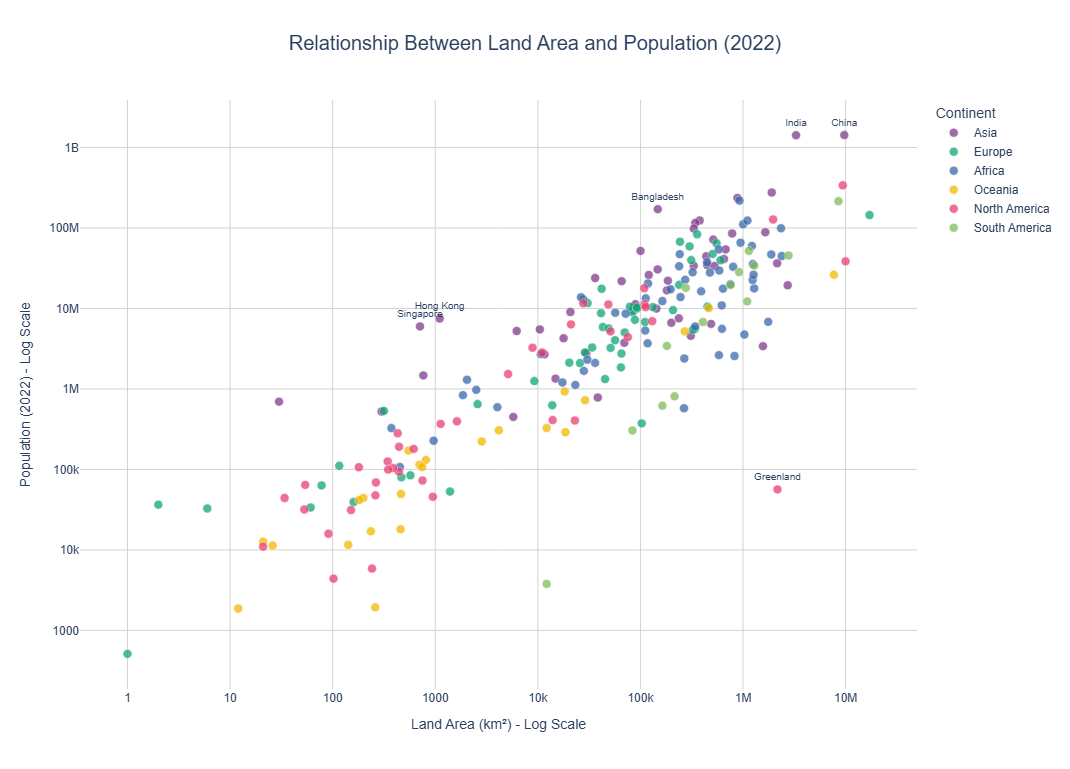

Q3: LAND AREA VS POPULATION ANALYSIS

Raw correlation: 0.453
Log-scale correlation: 0.872

Highlighted countries:
   Country     Continent    Area  2022 Population
Bangladesh          Asia  147570        171186372
     China          Asia 9706961       1425887337
 Greenland North America 2166086            56466
 Hong Kong          Asia    1104          7488865
     India          Asia 3287590       1417173173
 Singapore          Asia     710          5975689


In [6]:
# 1. Prepare data
q3_data = df.copy()

# Remove invalid or missing values
q3_data = q3_data.dropna(
    subset=['Area', '2022 Population', 'Country', 'Continent']
)

q3_data = q3_data[
    (q3_data['Area'] > 0) &
    (q3_data['2022 Population'] > 0)
].copy()

# 2. Select countries to highlight
highlight_countries = [
    'Bangladesh',
    'Singapore',
    'Hong Kong',
    'India',
    'China',
    'Greenland'
]

q3_data['Label'] = q3_data['Country'].where(
    q3_data['Country'].isin(highlight_countries),
    ''
)

# 3. Calculate correlations
pearson_raw = q3_data['Area'].corr(
    q3_data['2022 Population']
)

pearson_log = np.log10(q3_data['Area']).corr(
    np.log10(q3_data['2022 Population'])
)

# 4. Create scatter plot
fig = px.scatter(
    q3_data,
    x='Area',
    y='2022 Population',
    color='Continent',
    text='Label',
    log_x=True,
    log_y=True,
    hover_name='Country',
    hover_data={
        'Continent': True,
        'Area': ':,',
        '2022 Population': ':,',
        'Label': False
    },
    color_discrete_sequence=px.colors.qualitative.Bold,
    title='Relationship Between Land Area and Population (2022)',
    labels={
        'Area': 'Land Area (km²)',
        '2022 Population': 'Population (2022)',
        'Continent': 'Continent'
    },
    template='plotly_white'
)

# 5. Improve marker appearance
fig.update_traces(
    marker=dict(
        size=9,
        opacity=0.75,
        line=dict(width=0.5, color='white')
    ),
    textposition='top center',
    textfont=dict(size=10),
    selector=dict(mode='markers+text')
)

# 6. Professional layout
fig.update_layout(
    title=dict(
        x=0.5,
        xanchor='center',
        font=dict(size=20)
    ),
    height=750,
    width=1100,
    font=dict(family='Arial', size=12),
    legend_title_text='Continent',
    xaxis=dict(
        title='Land Area (km²) - Log Scale',
        showgrid=True,
        gridcolor='lightgrey'
    ),
    yaxis=dict(
        title='Population (2022) - Log Scale',
        showgrid=True,
        gridcolor='lightgrey'
    ),
    plot_bgcolor='white',
    paper_bgcolor='white'
)

fig.show()

# 7. Display analysis
print("=" * 55)
print("Q3: LAND AREA VS POPULATION ANALYSIS")
print("=" * 55)

print(f"\nRaw correlation: {pearson_raw:.3f}")
print(f"Log-scale correlation: {pearson_log:.3f}")

print("\nHighlighted countries:")
print(
    q3_data[
        q3_data['Country'].isin(highlight_countries)
    ][['Country', 'Continent', 'Area', '2022 Population']]
    .to_string(index=False)
)


---
## Q4 — How crowded are the continents?

How does **population density vary within and across continents**? Show the spread, not just the average.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* : I chose a box plot because it shows the distribution and variation of population density across different continents. It displays the median, quartiles, spread and outliers, making it easier to compare how crowded countries are within each continent. I used different colours for continents and a logarithmic scale to make differences in population density easier to observe.

Q4: POPULATION DENSITY ANALYSIS

Population density statistics (people per km²):
               count  median     mean   min       max
Continent                                            
Africa            57   59.71   125.05  2.17    871.93
Asia              50  122.97  1025.02  2.17  23172.27
Europe            50  106.87   663.32  3.62  18234.50
North America     40  221.42   272.76  0.03   1299.26
Oceania           23   78.25   132.54  3.40    603.24
South America     14   17.79    20.97  0.31     65.02


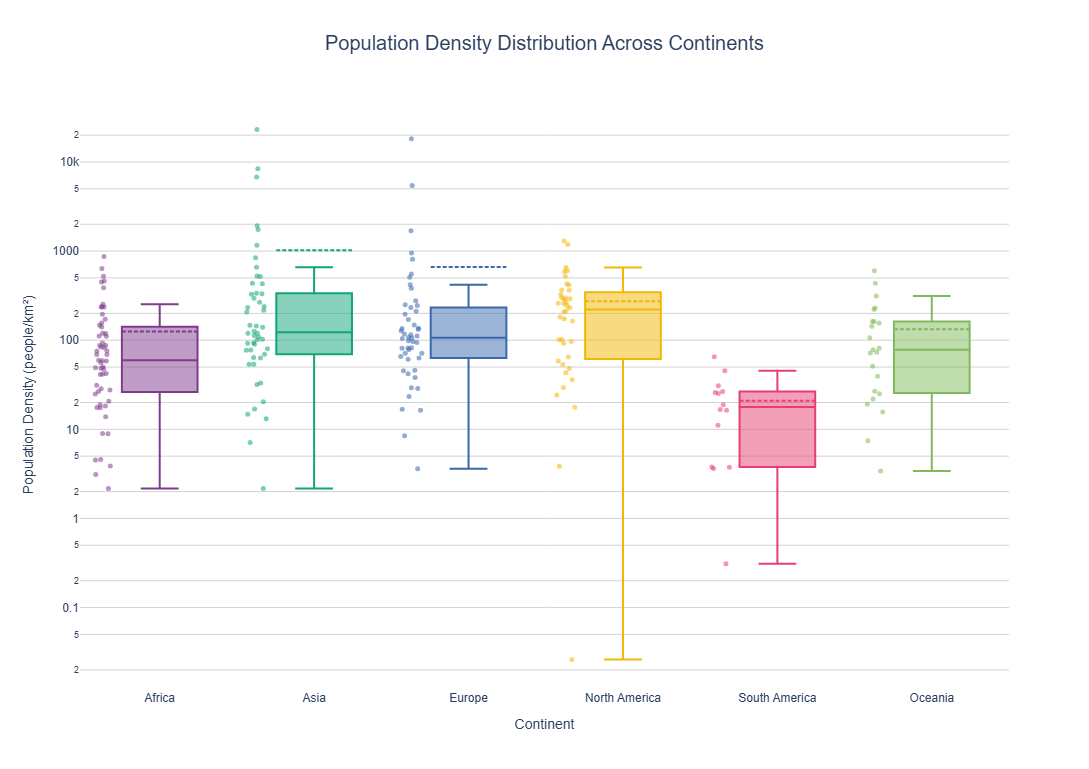


Most densely populated country:
Country           Macau
Continent          Asia
Density      23172.2667
Name: 119, dtype: object


In [7]:
# 1. Prepare population density data
q4_data = df.dropna(
    subset=['Continent', 'Density']
).copy()

# Remove invalid density values
q4_data = q4_data[q4_data['Density'] > 0]

# 2. Define continent order
continent_order = [
    'Africa',
    'Asia',
    'Europe',
    'North America',
    'South America',
    'Oceania'
]

# 3. Calculate descriptive statistics
density_stats = q4_data.groupby(
    'Continent'
)['Density'].agg(
    ['count', 'median', 'mean', 'min', 'max']
).round(2)

print("=" * 60)
print("Q4: POPULATION DENSITY ANALYSIS")
print("=" * 60)

print("\nPopulation density statistics (people per km²):")
print(density_stats)

# 4. Create box plot
fig = px.box(
    q4_data,
    x='Continent',
    y='Density',
    color='Continent',
    points='all',
    category_orders={'Continent': continent_order},
    color_discrete_sequence=px.colors.qualitative.Bold,
    title='Population Density Distribution Across Continents',
    labels={
        'Continent': 'Continent',
        'Density': 'Population Density (people/km²)'
    },
    template='plotly_white',
    hover_data=['Country']
)

# 5. Improve chart appearance
fig.update_traces(
    marker=dict(
        size=5,
        opacity=0.55
    ),
    line=dict(width=2),
    boxmean=True
)

# 6. Professional layout
fig.update_layout(
    title=dict(
        x=0.5,
        xanchor='center',
        font=dict(size=20)
    ),
    height=750,
    width=1100,
    font=dict(family='Arial', size=12),
    showlegend=False,
    xaxis=dict(
        title='Continent',
        showgrid=False
    ),
    yaxis=dict(
        title='Population Density (people/km²)',
        type='log',
        showgrid=True,
        gridcolor='lightgrey'
    ),
    plot_bgcolor='white',
    paper_bgcolor='white'
)

# 7. Display chart
fig.show()

# 8. Identify most densely populated country
densest = q4_data.loc[q4_data['Density'].idxmax()]

print("\nMost densely populated country:")
print(densest[['Country', 'Continent', 'Density']])


---
## Q5 — Where did populations grow — and where did they shrink?

Which countries' populations **grew and which shrank between 2000 and 2022** (percentage change), and where in the world are they?

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* : I chose a choropleth map because it shows population percentage changes geographically across the world. I calculated the percentage change between 2000 and 2022 to compare countries of different population sizes fairly. I used a diverging colour scale, with different colours representing population growth and decline, and centred the scale at zero to make the differences easy to identify. Hover information provides the country name and percentage change.

Q5: WORLD POPULATION GROWTH ANALYSIS

Countries with population growth: 200
Countries with population decline: 34
Countries with no change: 0


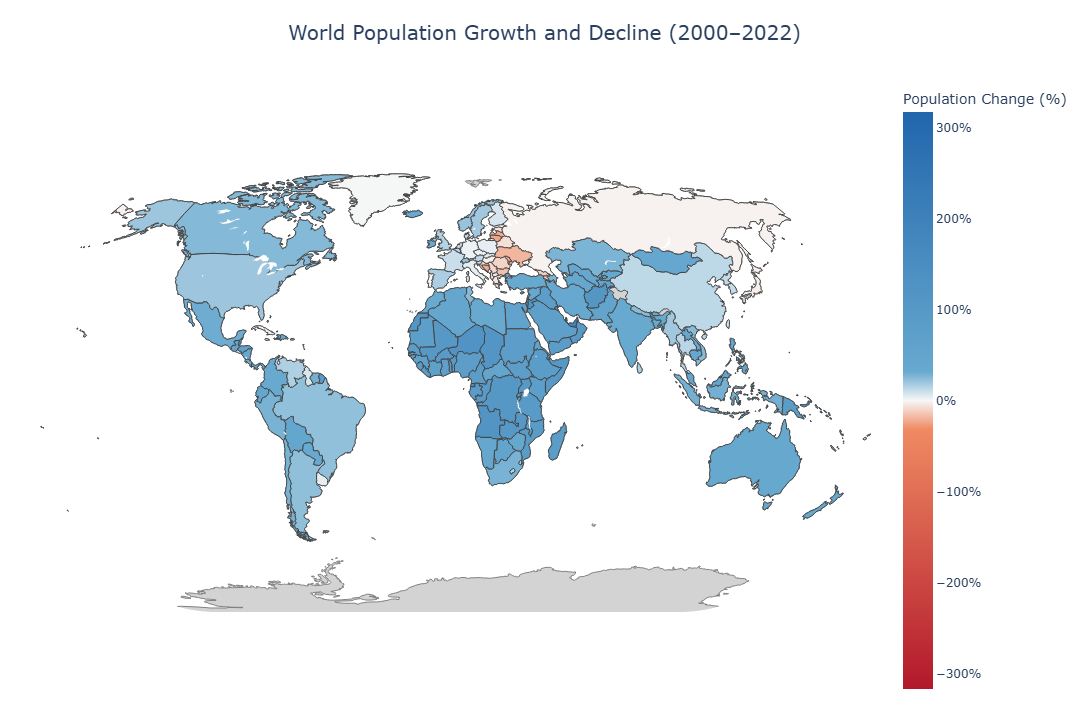


Top 10 countries with highest population growth:
                 Country  Population Change (%)
                   Qatar             317.242239
    United Arab Emirates             188.249439
       Equatorial Guinea             144.520327
Turks and Caicos Islands             143.827358
                   Niger             125.490255
                  Jordan             123.209664
                  Kuwait             120.624880
                  Angola             117.084619
                    Chad             114.590398
          Western Sahara             113.032270

Top 10 countries with largest population decline:
                 Country  Population Change (%)
Northern Mariana Islands             -38.321840
          American Samoa             -23.968745
               Lithuania             -23.601880
        Marshall Islands             -23.338374
                 Moldova             -23.016822
                  Latvia             -22.648786
  Bosnia and Herzegovina           

In [8]:
# 1. Prepare data
q5_data = df.copy()

# Remove missing values
q5_data = q5_data.dropna(
    subset=['CCA3', 'Country', '2000 Population',
            '2022 Population']
).copy()

# 2. Calculate percentage population change
q5_data['Population Change (%)'] = (
    (q5_data['2022 Population'] - q5_data['2000 Population'])
    / q5_data['2000 Population']
) * 100

# 3. Separate growing and shrinking countries
growing = q5_data[
    q5_data['Population Change (%)'] > 0
]

shrinking = q5_data[
    q5_data['Population Change (%)'] < 0
]

# 4. Calculate summary statistics
print("=" * 60)
print("Q5: WORLD POPULATION GROWTH ANALYSIS")
print("=" * 60)

print("\nCountries with population growth:", len(growing))
print("Countries with population decline:", len(shrinking))
print("Countries with no change:",
      (q5_data['Population Change (%)'] == 0).sum())

# 5. Create choropleth world map
fig = px.choropleth(
    q5_data,
    locations='CCA3',
    locationmode='ISO-3',
    color='Population Change (%)',
    hover_name='Country',
    hover_data={
        'CCA3': False,
        '2000 Population': ':,',
        '2022 Population': ':,',
        'Population Change (%)': ':.2f'
    },
    color_continuous_scale=[
        [0, '#B2182B'],
        [0.45, '#EF8A62'],
        [0.5, '#F7F7F7'],
        [0.55, '#67A9CF'],
        [1, '#2166AC']
    ],
    color_continuous_midpoint=0,
    title='World Population Growth and Decline (2000–2022)',
    labels={
        'Population Change (%)': 'Population Change (%)'
    }
)

# 6. Improve map appearance
fig.update_geos(
    showframe=False,
    showcoastlines=True,
    coastlinecolor='grey',
    showland=True,
    landcolor='lightgrey',
    showocean=True,
    oceancolor='white',
    projection_type='natural earth'
)

fig.update_layout(
    title=dict(
        x=0.5,
        xanchor='center',
        font=dict(size=20)
    ),
    height=700,
    width=1100,
    coloraxis_colorbar=dict(
        title='Population Change (%)',
        ticksuffix='%'
    ),
    margin=dict(l=20, r=20, t=80, b=20)
)

# 7. Display map
fig.show()

# 8. Show countries with highest growth and decline
print("\nTop 10 countries with highest population growth:")
print(
    q5_data.nlargest(
        10, 'Population Change (%)'
    )[['Country', 'Population Change (%)']].to_string(index=False)
)

print("\nTop 10 countries with largest population decline:")
print(
    q5_data.nsmallest(
        10, 'Population Change (%)'
    )[['Country', 'Population Change (%)']].to_string(index=False)
)


---
## Q6 — Where do the world's 8 billion people live?

How is the **2022 world population** distributed across **continents and the countries within them**? Show both levels in one figure.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* : I chose a treemap because it effectively displays hierarchical population data at two levels: continents and individual countries. The size of each rectangle represents the country's 2022 population, while colours distinguish the continents. This makes it easy to compare population sizes between countries and understand how each continent contributes to the total world population. I used clear labels and hover information to improve readability.

Q6: WORLD POPULATION DISTRIBUTION

Total world population (2022): 7,973,413,042

Population by continent:
Continent
Asia             4721383274
Africa           1426730932
Europe            743147538
North America     600296136
South America     436816608
Oceania            45038554


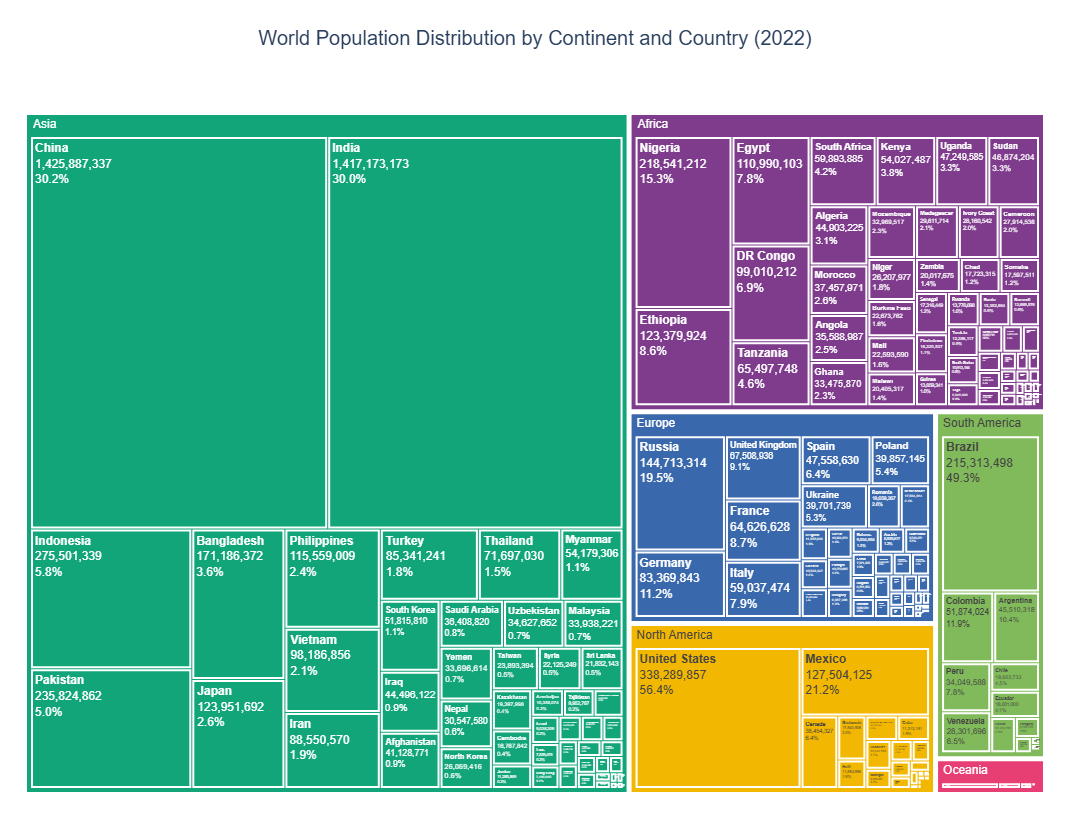


Top 10 most populated countries in 2022:
      Country     Continent  2022 Population
        China          Asia       1425887337
        India          Asia       1417173173
United States North America        338289857
    Indonesia          Asia        275501339
     Pakistan          Asia        235824862
      Nigeria        Africa        218541212
       Brazil South America        215313498
   Bangladesh          Asia        171186372
       Russia        Europe        144713314
       Mexico North America        127504125

Continental share of world population:
Continent
Asia             59.21
Africa           17.89
Europe            9.32
North America     7.53
South America     5.48
Oceania           0.56


In [9]:
# 1. Prepare data
q6_data = df.dropna(
    subset=['Continent', 'Country', '2022 Population']
).copy()

q6_data = q6_data[
    q6_data['2022 Population'] > 0
].copy()

# 2. Calculate total world population
world_population = q6_data['2022 Population'].sum()

print("=" * 60)
print("Q6: WORLD POPULATION DISTRIBUTION")
print("=" * 60)

print(f"\nTotal world population (2022): {world_population:,.0f}")

# 3. Calculate population by continent
continent_population = q6_data.groupby(
    'Continent'
)['2022 Population'].sum().sort_values(ascending=False)

print("\nPopulation by continent:")
print(continent_population.to_string())

# 4. Create treemap
fig = px.treemap(
    q6_data,
    path=['Continent', 'Country'],
    values='2022 Population',
    color='Continent',
    color_discrete_sequence=px.colors.qualitative.Bold,
    title='World Population Distribution by Continent and Country (2022)',
    hover_data={
        '2022 Population': ':,'
    }
)

# 5. Improve treemap appearance
fig.update_traces(
    textinfo='label+value+percent parent',
    texttemplate='<b>%{label}</b><br>%{value:,.0f}<br>%{percentParent:.1%}',
    hovertemplate=(
        '<b>%{label}</b><br>'
        'Population: %{value:,.0f}<br>'
        'Share of parent: %{percentParent:.2%}'
        '<extra></extra>'
    ),
    marker=dict(
        line=dict(
            color='white',
            width=2
        )
    )
)

# 6. Professional layout
fig.update_layout(
    title=dict(
        x=0.5,
        xanchor='center',
        font=dict(size=20)
    ),
    height=800,
    width=1150,
    margin=dict(
        t=90,
        l=20,
        r=20,
        b=20
    ),
    font=dict(
        family='Arial',
        size=12
    )
)

# 7. Display chart
fig.show()

# 8. Show top 10 populated countries
print("\nTop 10 most populated countries in 2022:")

print(
    q6_data.nlargest(
        10, '2022 Population'
    )[['Country', 'Continent', '2022 Population']]
    .to_string(index=False)
)

# 9. Show continental population percentages
print("\nContinental share of world population:")

continent_share = (
    continent_population / world_population * 100
).round(2)

print(continent_share.to_string())


---
## Q7 — Whose share of the world is rising?

How have the shares of world population held by **Africa, Asia and Europe** changed from 1970 to 2022? Group the other three continents as `'Rest of the world'`.

**Chart choice & justification:** *Which chart did you choose, and why? Justify design choices.

*YOUR ANSWER HERE* : I chose a 100% stacked bar chart because it shows how each continent's share contributes to the total world population in different years. Each bar represents 100% of the world population, allowing easy comparison of changes in population shares from 1970 to 2022. Africa, Asia and Europe are displayed separately, while the remaining continents are grouped as Rest of the world. Different colours distinguish the four groups.

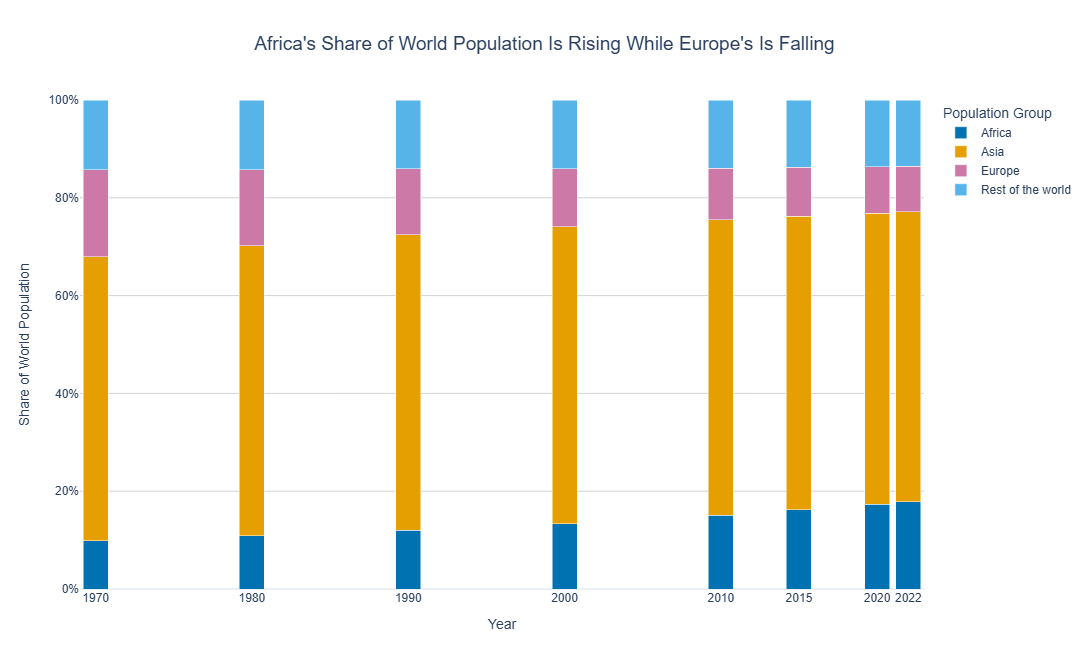

Q7: WORLD POPULATION SHARE ANALYSIS
Year                1970   2022  Change (percentage points)
Group                                                      
Africa              9.89  17.89                        8.00
Asia               58.06  59.21                        1.15
Europe             17.76   9.32                       -8.44
Rest of the world  14.29  13.57                       -0.72


In [10]:

# Q7 - Whose share of the world is rising?

# Prepare data
q7_data = df_long.copy()

# Group the continents
q7_data['Group'] = q7_data['Continent'].apply(
    lambda x: x if x in ['Africa', 'Asia', 'Europe']
    else 'Rest of the world'
)

# Calculate population by year and group
grouped_pop = q7_data.groupby(
    ['Year', 'Group']
)['Population'].sum().reset_index()

# Calculate total world population per year
yearly_total = grouped_pop.groupby(
    'Year'
)['Population'].transform('sum')

# Calculate world population share
grouped_pop['World Share (%)'] = (
    grouped_pop['Population'] / yearly_total
) * 100

# Set group order
group_order = [
    'Africa',
    'Asia',
    'Europe',
    'Rest of the world'
]

# Colourblind-friendly palette
group_colors = {
    'Africa': '#0072B2',
    'Asia': '#E69F00',
    'Europe': '#CC79A7',
    'Rest of the world': '#56B4E9'
}

# Create 100% stacked bar chart
fig = px.bar(
    grouped_pop,
    x='Year',
    y='World Share (%)',
    color='Group',
    barmode='stack',
    category_orders={'Group': group_order},
    color_discrete_map=group_colors,
    title="Africa's Share of World Population Is Rising While Europe's Is Falling",
    labels={
        'Year': 'Year',
        'World Share (%)': 'Share of World Population',
        'Group': 'Population Group'
    },
    template='plotly_white'
)

# Format bars
fig.update_traces(
    hovertemplate=(
        '<b>%{fullData.name}</b><br>'
        'Year: %{x}<br>'
        'World share: %{y:.2f}%'
        '<extra></extra>'
    )
)

# Improve layout
fig.update_layout(
    title=dict(
        x=0.5,
        xanchor='center',
        font=dict(size=19)
    ),
    height=650,
    width=1100,
    font=dict(family='Arial', size=12),
    xaxis=dict(
        title='Year',
        tickmode='array',
        tickvals=sorted(grouped_pop['Year'].unique())
    ),
    yaxis=dict(
        title='Share of World Population',
        ticksuffix='%',
        range=[0, 100],
        dtick=20,
        showgrid=True,
        gridcolor='lightgrey'
    ),
    legend_title_text='Population Group',
    plot_bgcolor='white',
    paper_bgcolor='white'
)

fig.show()

# Compare 1970 and 2022
comparison = grouped_pop[
    grouped_pop['Year'].isin([1970, 2022])
].pivot(
    index='Group',
    columns='Year',
    values='World Share (%)'
)

comparison['Change (percentage points)'] = (
    comparison[2022] - comparison[1970]
)

print("Q7: WORLD POPULATION SHARE ANALYSIS")
print(comparison.round(2).to_string())
